# Heston Stochastic-Volatility Benchmark: COS Calibration, Rolling Pricing and Delta Hedging

This notebook implements the **minimal strong Heston baseline** selected after the March 2024 SPX experiments:

$$
\text{IvyDB cleaning}
\rightarrow \text{five-parameter Heston}
\rightarrow \text{vectorised COS prices}
\rightarrow \text{vega-normalised least squares}
\rightarrow \text{daily warm starts}
\rightarrow \text{frozen next-day pricing}
\rightarrow \text{spot-delta hedging}.
$$

The goal is not to force Heston to fit every SPX quote. It is to give the neural-SDE benchmark a strong, interpretable **classical stochastic-volatility** comparator without retaining machinery that did not improve the rolling experiment.

The cleaning universe and one-day hedge accounting deliberately match the local-volatility notebook.

## 1. Imports, paths and visible configuration

In [2]:
from pathlib import Path
from dataclasses import dataclass
import hashlib, json, os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from scipy.interpolate import PchipInterpolator
from scipy.optimize import least_squares
from scipy.stats import norm

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable=None, **kwargs):
        return iterable if iterable is not None else None

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

DATA_DIR = Path("/mnt/data") if Path("/mnt/data").exists() else Path.cwd()

def resolve_data_file(*names):
    for name in names:
        path = DATA_DIR / name
        if path.exists(): return path
    raise FileNotFoundError(f"None of these files exists in {DATA_DIR}: {names}")

FILES = {
    "options": resolve_data_file(
        "one_month_spx_option_price.csv"
    ),
    "forwards": resolve_data_file(
        "one_month_spx_forward_price.csv"
    ),
    "spot": resolve_data_file(
        "one_month_spx_security_price.csv"
    ),
    "rates": resolve_data_file(
        "one_month_spx_zero_coupon_yield_curve.csv"
    ),
}

CACHE_DIR = DATA_DIR / "heston_cache_v1"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Common SPX cleaning: deliberately the same as the current LV notebook.
SECID = 108105
MIN_DTE, MAX_DTE = 7, 365
MAX_ABS_LOG_MONEYNESS = 0.30
MIN_ABS_DELTA, MAX_ABS_DELTA = 0.05, 0.95
MAX_RELATIVE_SPREAD = 0.25
ATM_TIGHTER_SIDE_BAND = 0.05
MIN_POINTS_PER_SLICE = 8

# Heston/COS settings selected from the pilot experiment.
MAX_QUOTES_PER_SLICE = 25
COS_N_CALIBRATION = 96
COS_N_EVALUATION = 128
COS_L = 15
VEGA_FLOOR = 5.0

N_STARTS_FIRST_DAY = 6
N_STARTS_LATER = 2
CALIBRATION_MAX_NFEV = 400
CALIBRATION_TOL = 1e-8

# Broad numerical safety bounds, not Feller restrictions.
PARAM_BOUNDS = {
    "v0": (0.0025, 0.25),
    "theta": (0.0025, 0.25),
    "kappa": (0.05, 15.0),
    "xi": (0.05, 3.0),
    "rho": (-0.995, 0.20),
}

EXAMPLE_DATE = None
RUN_ROLLING_BACKTEST = True
MAX_ROLLING_TRANSITIONS = None

FORCE_REBUILD_CLEANING = False
FORCE_RECALIBRATE_HESTON = False
FORCE_REBUILD_ROLLING = False

CACHE_VERSION = "heston_cos_vega_loss_warmstart_v1"

## 2. Fingerprinted caches

The first run performs the calculations. Later runs reuse cleaned data, completed daily Heston calibrations and the rolling backtest only when the input files and relevant settings have the same fingerprint.

Daily parameters are written after each completed valuation date, so an interrupted calibration can resume.

In [3]:
def sha256_file(path, chunk_size=2**20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

def stable_hash(obj):
    payload = json.dumps(obj, sort_keys=True, default=str, separators=(",", ":"))
    return hashlib.sha256(payload.encode()).hexdigest()

def atomic_pickle(df, path):
    path = Path(path); tmp = path.with_suffix(path.suffix + ".tmp")
    df.to_pickle(tmp); os.replace(tmp, path)

file_hashes = {name: sha256_file(path) for name, path in FILES.items()}
cleaning_config = {
    "version": CACHE_VERSION, "secid": SECID, "min_dte": MIN_DTE, "max_dte": MAX_DTE,
    "max_abs_k": MAX_ABS_LOG_MONEYNESS, "min_abs_delta": MIN_ABS_DELTA,
    "max_abs_delta": MAX_ABS_DELTA, "max_relative_spread": MAX_RELATIVE_SPREAD,
    "atm_band": ATM_TIGHTER_SIDE_BAND, "min_points": MIN_POINTS_PER_SLICE,
}
calibration_config = {
    **cleaning_config, "max_quotes_per_slice": MAX_QUOTES_PER_SLICE,
    "cos_n_calibration": COS_N_CALIBRATION, "cos_n_evaluation": COS_N_EVALUATION,
    "cos_l": COS_L, "vega_floor": VEGA_FLOOR, "bounds": PARAM_BOUNDS,
    "n_starts_first": N_STARTS_FIRST_DAY, "n_starts_later": N_STARTS_LATER,
    "max_nfev": CALIBRATION_MAX_NFEV, "tol": CALIBRATION_TOL,
}
cleaning_fingerprint = stable_hash({"files": file_hashes, "config": cleaning_config})[:16]
heston_fingerprint = stable_hash({"files": file_hashes, "config": calibration_config})[:16]

CLEAN_QUOTES_CACHE = CACHE_DIR / f"quotes_{cleaning_fingerprint}.pkl"
CLEAN_OTM_CACHE = CACHE_DIR / f"otm_{cleaning_fingerprint}.pkl"
PARAM_CACHE = CACHE_DIR / f"params_{heston_fingerprint}.pkl"
ROLLING_CACHE = CACHE_DIR / f"rolling_{heston_fingerprint}.pkl"

print("Cleaning fingerprint:", cleaning_fingerprint)
print("Heston fingerprint:", heston_fingerprint)

Cleaning fingerprint: b9b9d1849a3e6ccd
Heston fingerprint: 7bd0c09591fdc99f


## 3. Load the four IvyDB files

In [4]:
options_raw = pd.read_csv(FILES["options"], low_memory=False)
forwards_raw = pd.read_csv(FILES["forwards"], low_memory=False)
spot_raw = pd.read_csv(FILES["spot"], low_memory=False)
rates_raw = pd.read_csv(FILES["rates"], low_memory=False)

print({"options": len(options_raw), "forwards": len(forwards_raw), "spot": len(spot_raw), "rates": len(rates_raw)})

{'options': 326964, 'forwards': 1192, 'spot': 20, 'rates': 220}


## 4. Common SPX cleaning and the OTM calibration strip

This is intentionally the same preliminary universe as the LV notebook:

- SPX, European, standard unadjusted contracts;
- 7--365 calendar days to expiry;
- relative spread at most 25%;
- $0.05\leq|\Delta_{\rm IvyDB}|\leq0.95$;
- $|\log(K/F)|\leq0.30$;
- elementary European price bounds;
- one OTM observation per strike, with the tighter side preferred near ATM.

Calls and puts contain essentially the same risk-neutral information through put--call parity. Heston is therefore calibrated to the OTM strip, while later evaluation uses the complete cleaned call-and-put universe.

In [5]:
def prepare_clean_data(options_raw, forwards_raw, spot_raw, rates_raw):
    options = options_raw.copy()
    options["date"] = pd.to_datetime(options["date"]); options["exdate"] = pd.to_datetime(options["exdate"])
    options["K"] = options["strike_price"] / 1000.0
    options["T_days"] = (options["exdate"] - options["date"]).dt.days; options["T"] = options["T_days"] / 365.0
    options["bid"] = pd.to_numeric(options["best_bid"], errors="coerce")
    options["ask"] = pd.to_numeric(options["best_offer"], errors="coerce")
    options["mid"] = 0.5 * (options["bid"] + options["ask"])
    options["spread"] = options["ask"] - options["bid"]
    options["relative_spread"] = options["spread"] / options["mid"].replace(0, np.nan)
    options["iv_market"] = pd.to_numeric(options["impl_volatility"], errors="coerce")
    options["delta_market"] = pd.to_numeric(options["delta"], errors="coerce")
    options["abs_delta_market"] = options["delta_market"].abs()

    mask = (
        (options["secid"] == SECID) & (options["exercise_style"] == "E") &
        (options["contract_size"] == 100) & (options["cfadj"] == 1) & options["cp_flag"].isin(["C", "P"]) &
        (options["bid"] >= 0) & (options["ask"] > options["bid"]) & (options["mid"] > 0) &
        options["T_days"].between(MIN_DTE, MAX_DTE) & options["iv_market"].between(1e-4, 5.0) &
        options["abs_delta_market"].between(MIN_ABS_DELTA, MAX_ABS_DELTA) &
        (options["relative_spread"] <= MAX_RELATIVE_SPREAD)
    )
    options = options.loc[mask].copy()

    spot = spot_raw.loc[spot_raw["secid"] == SECID, ["date", "close"]].copy()
    spot["date"] = pd.to_datetime(spot["date"]); spot = spot.rename(columns={"close": "S"}).drop_duplicates("date")

    forwards = forwards_raw.loc[forwards_raw["secid"] == SECID].copy()
    forwards["date"] = pd.to_datetime(forwards["date"]); forwards["expiration"] = pd.to_datetime(forwards["expiration"])
    forwards = forwards.rename(columns={"expiration": "exdate", "AMSettlement": "am_settlement", "ForwardPrice": "F"})
    forwards = forwards[["date", "exdate", "am_settlement", "F"]].drop_duplicates(["date", "exdate", "am_settlement"])

    rates = rates_raw.copy(); rates["date"] = pd.to_datetime(rates["date"])
    rates["days"] = pd.to_numeric(rates["days"], errors="coerce")
    rates["rate_decimal"] = pd.to_numeric(rates["rate"], errors="coerce") / 100.0
    rate_curves = {
        d: (g["days"].to_numpy(float), g["rate_decimal"].to_numpy(float))
        for d, g in rates.dropna().sort_values(["date", "days"]).groupby("date")
    }

    options = options.merge(spot, on="date", how="left").merge(
        forwards, on=["date", "exdate", "am_settlement"], how="left", validate="many_to_one"
    )
    options["r"] = [
        float(np.interp(n, *rate_curves[d])) if d in rate_curves else np.nan
        for d, n in zip(options["date"], options["T_days"])
    ]
    options["D"] = np.exp(-options["r"] * options["T"])
    options["carry"] = np.log(options["F"] / options["S"]) / options["T"]
    options["q"] = options["r"] - options["carry"]
    options["k"] = np.log(options["K"] / options["F"])
    options = options.dropna(subset=["S", "F", "r", "D", "carry", "k"])
    options = options.loc[options["k"].abs() <= MAX_ABS_LOG_MONEYNESS].copy()

    call_lb = options["D"] * np.maximum(options["F"] - options["K"], 0.0)
    call_ub = options["D"] * options["F"]
    put_lb = options["D"] * np.maximum(options["K"] - options["F"], 0.0)
    put_ub = options["D"] * options["K"]
    lb = np.where(options["cp_flag"].eq("C"), call_lb, put_lb)
    ub = np.where(options["cp_flag"].eq("C"), call_ub, put_ub)
    options = options.loc[(options["mid"] >= lb - 1e-6) & (options["mid"] <= ub + 1e-6)].copy()

    return options.sort_values(["date", "exdate", "am_settlement", "K", "cp_flag"]).reset_index(drop=True)

def build_otm_surface(quotes):
    idx = ["date", "exdate", "am_settlement", "K", "T", "S", "F", "r", "q", "carry", "D", "k"]
    vals = ["mid", "bid", "ask", "spread", "relative_spread", "iv_market", "delta_market", "optionid"]

    wide = quotes.pivot_table(index=idx, columns="cp_flag", values=vals, aggfunc="first")
    wide.columns = [f"{a}_{b}" for a, b in wide.columns]
    wide = wide.reset_index()

    strict_call = wide["K"] >= wide["F"]
    near = wide["k"].abs() <= ATM_TIGHTER_SIDE_BAND
    have_c = wide.get("iv_market_C", pd.Series(np.nan, index=wide.index)).notna()
    have_p = wide.get("iv_market_P", pd.Series(np.nan, index=wide.index)).notna()
    c_spread = wide.get("spread_C", pd.Series(np.inf, index=wide.index))
    p_spread = wide.get("spread_P", pd.Series(np.inf, index=wide.index))

    choose_call = strict_call.copy()
    both_near = near & have_c & have_p
    choose_call = np.where(both_near, c_spread <= p_spread, choose_call)
    wide["cp_otm"] = np.where(choose_call, "C", "P")

    for base in vals:
        c = wide.get(f"{base}_C", pd.Series(np.nan, index=wide.index))
        p = wide.get(f"{base}_P", pd.Series(np.nan, index=wide.index))
        wide[f"{base}_otm"] = np.where(choose_call, c, p)

    wide = wide.dropna(subset=["iv_market_otm", "mid_otm"]).copy()
    sizes = wide.groupby(["date", "exdate", "am_settlement"]).size()
    valid = sizes[sizes >= MIN_POINTS_PER_SLICE].index

    return (
        wide.set_index(["date", "exdate", "am_settlement"]).loc[valid].reset_index()
        .sort_values(["date", "T", "k"]).reset_index(drop=True)
    )

if CLEAN_QUOTES_CACHE.exists() and CLEAN_OTM_CACHE.exists() and not FORCE_REBUILD_CLEANING:
    quotes_all = pd.read_pickle(CLEAN_QUOTES_CACHE)
    otm = pd.read_pickle(CLEAN_OTM_CACHE)
    print("Loaded cleaned-data cache.")
else:
    quotes_all = prepare_clean_data(options_raw, forwards_raw, spot_raw, rates_raw)
    otm = build_otm_surface(quotes_all)
    atomic_pickle(quotes_all, CLEAN_QUOTES_CACHE)
    atomic_pickle(otm, CLEAN_OTM_CACHE)
    print("Built and cached cleaned data.")

print("Quotes:", len(quotes_all), "OTM observations:", len(otm),
      "Slices:", otm.groupby(["date", "exdate", "am_settlement"]).ngroups,
      "Dates:", otm["date"].nunique())

Built and cached cleaned data.
Quotes: 192031 OTM observations: 91930 Slices: 809 Dates: 20


## 5. Forward Black--Scholes helpers

The observed forward and discount factor are treated as market inputs:

$$
F=S e^{(r-q)T},\qquad D=e^{-rT}.
$$

Black--Scholes is used here only for convention checks, vegas and implied-volatility diagnostics. The Heston price itself comes from the Heston characteristic function.

In [6]:
def bs_forward_price(cp_flag, F, K, T, D, sigma):
    F, K, T, D, sigma = np.broadcast_arrays(*map(lambda x: np.asarray(x, float), [F, K, T, D, sigma]))
    volT = np.maximum(sigma, 1e-12) * np.sqrt(np.maximum(T, 1e-16))
    d1 = (np.log(np.maximum(F, 1e-300) / np.maximum(K, 1e-300)) + 0.5 * volT**2) / volT
    d2 = d1 - volT
    call = D * (F * norm.cdf(d1) - K * norm.cdf(d2))
    put = D * (K * norm.cdf(-d2) - F * norm.cdf(-d1))
    return np.where(np.asarray(cp_flag) == "C", call, put)

def bs_forward_vega(F, K, T, D, sigma):
    F, K, T, D, sigma = np.broadcast_arrays(*map(lambda x: np.asarray(x, float), [F, K, T, D, sigma]))
    volT = np.maximum(sigma, 1e-12) * np.sqrt(np.maximum(T, 1e-16))
    d1 = (np.log(np.maximum(F, 1e-300) / np.maximum(K, 1e-300)) + 0.5 * volT**2) / volT
    return D * F * norm.pdf(d1) * np.sqrt(np.maximum(T, 0.0))

def bs_implied_vol_newton(cp_flag, price, F, K, T, D, start, n_iter=12):
    sigma = np.clip(np.asarray(start, float).copy(), 1e-4, 5.0)
    for _ in range(n_iter):
        value = bs_forward_price(cp_flag, F, K, T, D, sigma)
        vega = np.maximum(bs_forward_vega(F, K, T, D, sigma), 1e-8)
        sigma = np.clip(sigma - (value - price) / vega, 1e-4, 5.0)
    return sigma

quotes_all["bs_market_iv_price"] = bs_forward_price(
    quotes_all["cp_flag"], quotes_all["F"], quotes_all["K"], quotes_all["T"], quotes_all["D"], quotes_all["iv_market"]
)
quotes_all["market_iv_repricing_error"] = quotes_all["bs_market_iv_price"] - quotes_all["mid"]
print("Market-IV repricing MAE:", quotes_all["market_iv_repricing_error"].abs().mean())

Market-IV repricing MAE: 0.14517807990320855


## 6. Heston under the risk-neutral measure

The classical Heston model is

$$
\frac{dS_t}{S_t}=(r-q)\,dt+\sqrt{v_t}\,dW_t^S,
$$

$$
dv_t=\kappa(\theta-v_t)\,dt+\xi\sqrt{v_t}\,dW_t^v,
\qquad
d\langle W^S,W^v\rangle_t=\rho\,dt.
$$

The five daily calibrated quantities are:

- $v_0$: current variance state;
- $\theta$: long-run variance;
- $\kappa$: mean-reversion speed;
- $\xi$: volatility of variance ("vol-of-vol");
- $\rho$: spot/variance Brownian correlation.

The model has a known characteristic function for $\log(S_T/S_0)$. This is the central computational advantage over a generic stochastic-volatility SDE: European prices do **not** require Monte Carlo during calibration.

We do **not** impose the Feller condition $2\kappa\theta\geq\xi^2$. It is a sufficient strict-positivity condition for the CIR variance process, not a no-arbitrage requirement, and the empirical SPX calibrations systematically preferred parameters that violated it.

## 7. Vectorised COS Heston pricing

The COS method (Fang--Oosterlee) approximates the terminal log-price density on a finite interval $[a,b]$ by a cosine series. Heston supplies the Fourier coefficients through its characteristic function.

For many options at once, the summation index is one matrix dimension and the contracts are the other. NumPy therefore evaluates the whole strip without a Python loop over options.

The implementation below follows the same practical architecture as the `ted-love/Heston_Calibration` COS code, with the stable $g=(W-d)/(W+d)$ characteristic-function representation.

In [7]:
def cos_chi(k, a, b, c, d):
    u = k * np.pi / (b - a)
    return (
        np.cos(u * (d-a)) * np.exp(d) - np.cos(u * (c-a)) * np.exp(c)
        + u * np.sin(u * (d-a)) * np.exp(d) - u * np.sin(u * (c-a)) * np.exp(c)
    ) / (1.0 + u*u)

def cos_psi(k, a, b, c, d):
    u = k * np.pi / (b - a)
    safe_u = u.copy(); safe_u[0, :] = 1.0
    out = (np.sin(safe_u * (d-a)) - np.sin(safe_u * (c-a))) / safe_u
    out[0, :] = d - c
    return out

def heston_truncation(L, T, r, q, theta, v0, xi, rho, kappa):
    T, r, q = np.broadcast_arrays(np.asarray(T, float), np.asarray(r, float), np.asarray(q, float))
    e = np.exp(-kappa*T)
    c1 = (r-q)*T + (1-e)*(theta-v0)/(2*kappa) - 0.5*theta*T

    c2 = (
        xi*T*kappa*e*(v0-theta)*(8*kappa*rho-4*xi)
        + kappa*rho*xi*(1-e)*(16*theta-8*v0)
        + 2*theta*kappa*T*(-4*kappa*rho*xi + xi*xi + 4*kappa*kappa)
        + xi*xi*((theta-2*v0)*np.exp(-2*kappa*T) + theta*(6*e-7) + 2*v0)
        + 8*kappa*kappa*(v0-theta)*(1-e)
    ) / (8*kappa**3)

    width = L * np.sqrt(np.maximum(np.abs(c2), 1e-14))
    return c1 - width, c1 + width

def heston_characteristic_function(u, T, r, q, v0, theta, kappa, xi, rho):
    W = kappa - 1j*rho*xi*u
    d = np.sqrt(W*W + xi*xi*(u*u + 1j*u))
    g = (W-d) / (W+d)
    edt = np.exp(-d*T)

    C = (
        1j*u*(r-q)*T
        + (kappa*theta/xi**2) * ((W-d)*T - 2*np.log((1-g*edt)/(1-g)))
    )
    D = ((W-d)/xi**2) * ((1-edt)/(1-g*edt))
    return np.exp(C + D*v0)

def heston_cos_price_delta(S, K, T, r, q, cp_flag, v0, theta, kappa, xi, rho,
                           N=COS_N_EVALUATION, L=COS_L):
    K, T, r, q = np.broadcast_arrays(*map(lambda x: np.asarray(x, float), [K, T, r, q]))
    cp_flag = np.broadcast_to(np.asarray(cp_flag), K.shape)

    shape = K.shape
    K, T, r, q, cp_flag = [np.asarray(x).reshape(-1) for x in [K, T, r, q, cp_flag]]
    a, b = heston_truncation(L, T, r, q, theta, v0, xi, rho, kappa)

    k = np.arange(N, dtype=float)[:, None]
    u = k * np.pi / (b-a)
    phi = heston_characteristic_function(
        u, T[None, :], r[None, :], q[None, :], v0, theta, kappa, xi, rho
    )

    zero = np.zeros_like(a)
    U = (2.0/(b-a)) * (-cos_chi(k, a, b, a, zero) + cos_psi(k, a, b, a, zero))

    x = np.log(float(S) / K)
    integrand = phi * U * np.exp(1j*u*(x-a))
    discK = K * np.exp(-r*T)

    put = discK * np.real(0.5*integrand[0] + np.sum(integrand[1:], axis=0))

    # d/dS exp(iu log(S/K)) = (iu/S) exp(iu log(S/K)).
    delta_integrand = (1j*u/float(S)) * integrand
    put_delta = discK * np.real(0.5*delta_integrand[0] + np.sum(delta_integrand[1:], axis=0))

    call = put + float(S)*np.exp(-q*T) - K*np.exp(-r*T)
    call_delta = put_delta + np.exp(-q*T)

    price = np.where(cp_flag == "C", call, put)
    delta = np.where(cp_flag == "C", call_delta, put_delta)
    return price.reshape(shape), delta.reshape(shape)

## 8. Numerical regression tests

Two cheap tests are run before calibration:

1. as vol-of-vol $\xi$ approaches zero with $v_0=\theta=\sigma^2$, Heston should approach constant-volatility Black--Scholes;
2. increasing the COS truncation count should barely move prices at the scale of the empirical pricing errors.

In [8]:
test_S, test_T, test_sigma = 5000.0, 60/365, 0.20
test_K = np.array([4500.0, 5000.0, 5500.0])
test_r = np.full(3, 0.05); test_q = np.full(3, 0.01); test_cp = np.array(["C"]*3)

heston_test, _ = heston_cos_price_delta(
    test_S, test_K, test_T, test_r, test_q, test_cp,
    test_sigma**2, test_sigma**2, 1.5, 1e-4, -0.7, N=256
)
test_F = test_S * np.exp((test_r-test_q)*test_T)
test_D = np.exp(-test_r*test_T)
bs_test = bs_forward_price(test_cp, test_F, test_K, test_T, test_D, test_sigma)

display(pd.DataFrame({
    "K": test_K, "Heston_near_BS": heston_test,
    "BS": bs_test, "difference": heston_test-bs_test
}))
print("Maximum near-BS error:", np.max(np.abs(heston_test-bs_test)))

example_date = pd.Timestamp(EXAMPLE_DATE) if EXAMPLE_DATE is not None else pd.Timestamp(sorted(otm["date"].unique())[0])
probe = otm.loc[otm["date"] == example_date].head(500)
probe_start = [0.02, 0.04, 1.5, 0.5, -0.7]

p96, _ = heston_cos_price_delta(
    float(probe["S"].iloc[0]), probe["K"], probe["T"], probe["r"], probe["q"], probe["cp_otm"],
    *probe_start, N=96
)
p192, _ = heston_cos_price_delta(
    float(probe["S"].iloc[0]), probe["K"], probe["T"], probe["r"], probe["q"], probe["cp_otm"],
    *probe_start, N=192
)
print("COS N=96 vs N=192 RMS price difference:", np.sqrt(np.mean((p96-p192)**2)))

,K,Heston_near_BS,BS,difference
0,4500.0,543.267321,543.264741,0.002580
1,5000.0,177.795378,177.795166,0.000212
2,5500.0,29.345344,29.348788,-0.003444


Maximum near-BS error: 0.0034436003775049073
COS N=96 vs N=192 RMS price difference: 1.232447853782591e-05


## 9. Calibration loss, parameter coordinates and starts

### Vega-normalised price residual

For option $i$,

$$
e_i(\Theta)=
\frac{C_i^{Heston}(\Theta)-C_i^{mid}}
{\max(\mathrm{Vega}_i^{BS},\nu_{\min})}.
$$

Because

$$
dC \approx \mathrm{Vega}\,d\sigma,
$$

this is approximately an implied-volatility error while avoiding an IV inversion at every optimiser step. It also prevents expensive high-vega contracts from dominating raw dollar-price least squares.

### Parameter transformation

The optimiser works in coordinates

$$
v_0=e^{x_1},\quad \theta=e^{x_2},\quad
\kappa=e^{x_3},\quad \xi=e^{x_4},\quad
\rho=\tanh x_5.
$$

This changes coordinates, not the Heston model. Broad transformed bounds are retained only as numerical safety rails.

### Warm starts

The first day receives several economically different starts. Later dates use yesterday's fitted parameters first, plus a fresh surface-informed fallback.

In [9]:
def params_from_x(x):
    return np.exp(x[0]), np.exp(x[1]), np.exp(x[2]), np.exp(x[3]), np.tanh(x[4])

def x_from_params(v0, theta, kappa, xi, rho):
    return np.array([
        np.log(v0), np.log(theta), np.log(kappa), np.log(xi),
        np.arctanh(np.clip(rho, -0.999999, 0.999999))
    ])

LOWER_X = x_from_params(
    PARAM_BOUNDS["v0"][0], PARAM_BOUNDS["theta"][0], PARAM_BOUNDS["kappa"][0],
    PARAM_BOUNDS["xi"][0], PARAM_BOUNDS["rho"][0]
)
UPPER_X = x_from_params(
    PARAM_BOUNDS["v0"][1], PARAM_BOUNDS["theta"][1], PARAM_BOUNDS["kappa"][1],
    PARAM_BOUNDS["xi"][1], PARAM_BOUNDS["rho"][1]
)

def sample_calibration_day(day, max_per_slice=MAX_QUOTES_PER_SLICE):
    pieces = []
    for _, g in day.groupby(["exdate", "am_settlement"]):
        g = g.sort_values("k")
        if len(g) <= max_per_slice:
            pieces.append(g)
        else:
            idx = np.unique(np.round(np.linspace(0, len(g)-1, max_per_slice)).astype(int))
            pieces.append(g.iloc[idx])
    return pd.concat(pieces, ignore_index=True)

def surface_informed_start(day):
    idx = day.groupby(["exdate", "am_settlement"])["k"].apply(lambda s: s.abs().idxmin())
    atm = day.loc[idx.to_numpy()].sort_values("T")
    n = max(1, min(3, len(atm)))
    v0 = float(np.nanmedian(atm.head(n)["iv_market_otm"]**2))
    theta = float(np.nanmedian(atm.tail(n)["iv_market_otm"]**2))
    return np.array([v0, theta, 1.5, 0.5, -0.7])

def first_day_starts(day):
    p = surface_informed_start(day)
    candidates = [
        p,
        [p[0], p[1], 0.50, 0.30, -0.40],
        [p[0], p[1], 3.00, 0.80, -0.85],
        [0.8*p[0], 1.2*p[1], 1.00, 1.00, -0.60],
        [1.2*p[0], 0.8*p[1], 5.00, 0.50, -0.90],
        [p[0], p[1], 0.25, 1.20, -0.30],
    ]
    return [np.asarray(x, float) for x in candidates[:N_STARTS_FIRST_DAY]]

def later_day_starts(day, previous):
    starts = [np.asarray(previous, float), surface_informed_start(day)]
    return starts[:N_STARTS_LATER]

## 10. Daily nonlinear least-squares calibration

In [10]:
def calibrate_heston_day(day, starts):
    calib = sample_calibration_day(day)
    S = float(calib["S"].iloc[0])
    K = calib["K"].to_numpy(float); T = calib["T"].to_numpy(float)
    r = calib["r"].to_numpy(float); q = calib["q"].to_numpy(float)
    cp = calib["cp_otm"].to_numpy(); mid = calib["mid_otm"].to_numpy(float)

    vega = bs_forward_vega(calib["F"], K, T, calib["D"], calib["iv_market_otm"])
    scale = np.maximum(vega, VEGA_FLOOR)

    def residuals(x):
        v0, theta, kappa, xi, rho = params_from_x(x)
        price, _ = heston_cos_price_delta(
            S, K, T, r, q, cp, v0, theta, kappa, xi, rho,
            N=COS_N_CALIBRATION, L=COS_L
        )
        return (price-mid) / scale

    best = None
    for j, start in enumerate(starts):
        x0 = np.clip(x_from_params(*start), LOWER_X + 1e-10, UPPER_X - 1e-10)
        result = least_squares(
            residuals, x0, bounds=(LOWER_X, UPPER_X), method="trf",
            ftol=CALIBRATION_TOL, xtol=CALIBRATION_TOL, gtol=CALIBRATION_TOL,
            max_nfev=CALIBRATION_MAX_NFEV
        )
        objective = float(np.dot(result.fun, result.fun))
        if best is None or objective < best["objective"]:
            best = {"objective": objective, "result": result, "start_id": j}

    v0, theta, kappa, xi, rho = params_from_x(best["result"].x)
    return {
        "v0": v0, "theta": theta, "kappa": kappa, "xi": xi, "rho": rho,
        "feller_ratio": 2*kappa*theta/(xi*xi),
        "objective": best["objective"],
        "n_calibration_quotes": len(calib),
        "nfev": best["result"].nfev,
        "start_id": best["start_id"],
        "success": bool(best["result"].success),
    }

## 11. Incremental daily Heston cache

The progress bar is per valuation date because each date fits one five-parameter Heston surface. On the first uncached date several starts are checked. Every later date is warm-started from the preceding calibration and retains one fresh surface-informed fallback.

In [12]:
if PARAM_CACHE.exists() and not FORCE_RECALIBRATE_HESTON:
    heston_params = pd.read_pickle(PARAM_CACHE)
    print("Loaded", len(heston_params), "cached dates.")
else:
    heston_params = pd.DataFrame()

dates = list(pd.to_datetime(sorted(otm["date"].unique())))
done = set(pd.to_datetime(heston_params["date"].unique())) if len(heston_params) else set()

for date in tqdm(dates, desc="Calibrating Heston", unit="date"):
    if date in done:
        continue

    day = otm.loc[otm["date"] == date]
    previous_rows = (heston_params.loc[heston_params["date"] < date].sort_values("date")
                     if "date" in heston_params.columns else pd.DataFrame())

    if len(previous_rows):
        prev = previous_rows.iloc[-1][["v0", "theta", "kappa", "xi", "rho"]].to_numpy(float)
        starts = later_day_starts(day, prev)
    else:
        starts = first_day_starts(day)

    row = calibrate_heston_day(day, starts)
    row["date"] = date
    heston_params = pd.concat([heston_params, pd.DataFrame([row])], ignore_index=True)
    heston_params = heston_params.drop_duplicates("date", keep="last").sort_values("date")
    atomic_pickle(heston_params, PARAM_CACHE)

display(heston_params)
print("Cache:", PARAM_CACHE.name)

Loaded 20 cached dates.


Calibrating Heston:   0%|          | 0/20 [00:00<?, ?date/s]

,v0,theta,kappa,xi,rho,feller_ratio,objective,n_calibration_quotes,nfev,start_id,success,date
0,0.011201,0.054174,1.467550,0.763146,-0.498515,0.273023,0.033769,997,10,2,True,2024-03-01
1,0.012837,0.061440,1.144192,0.718044,-0.504904,0.272694,0.033973,1000,8,0,True,2024-03-04
2,0.015864,0.050693,1.551990,0.797368,-0.518301,0.247486,0.036750,1000,9,0,True,2024-03-05
3,0.015537,0.051340,1.530853,0.782343,-0.521442,0.256820,0.038441,1000,9,1,True,2024-03-06
4,0.015143,0.060796,1.107341,0.712733,-0.503313,0.265051,0.033884,1000,8,0,True,2024-03-07
5,0.015732,0.051247,1.645155,0.809875,-0.505315,0.257082,0.036311,1000,8,1,True,2024-03-08
6,0.017047,0.050545,1.642532,0.816645,-0.515239,0.248976,0.034378,1000,5,0,True,2024-03-11
7,0.012964,0.066666,1.109742,0.725881,-0.482181,0.280818,0.039603,1000,9,0,True,2024-03-12
8,0.012637,0.063270,1.243484,0.735385,-0.493839,0.290966,0.038228,975,10,1,True,2024-03-13
9,0.013922,0.049551,1.991065,0.858510,-0.534974,0.267715,0.026658,1000,8,0,True,2024-03-14


Cache: params_7bd0c09591fdc99f.pkl


## 12. Parameter diagnostics

The Feller ratio

$$
R_F=\frac{2\kappa\theta}{\xi^2}
$$

is reported as a diagnostic only. $R_F<1$ means the classical sufficient Feller strict-positivity condition is violated; it does **not** make the calibrated risk-neutral model arbitrageable.

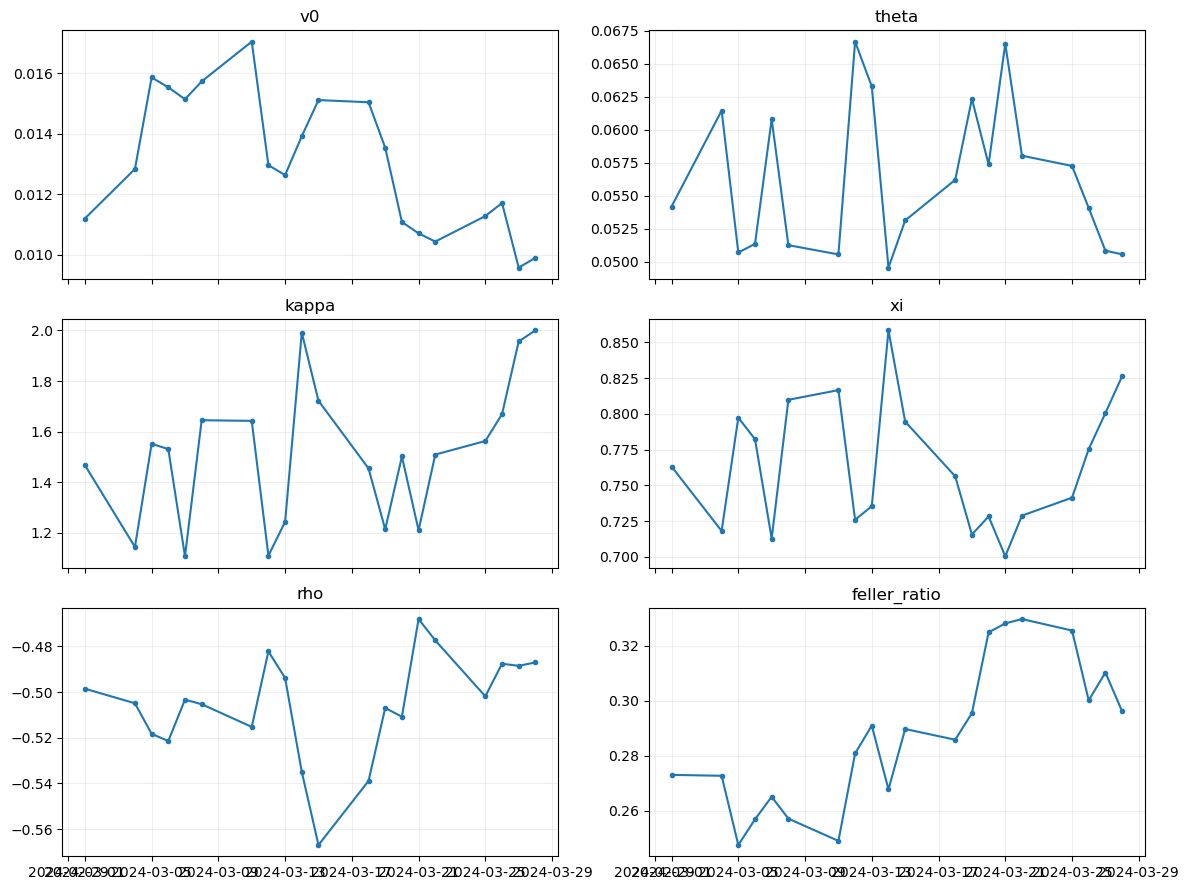

Feller-ratio range: 0.24748610580056463 to 0.32977827734217136


In [13]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
for ax, col in zip(axes.flat, ["v0", "theta", "kappa", "xi", "rho", "feller_ratio"]):
    ax.plot(heston_params["date"], heston_params[col], marker="o", ms=3)
    ax.set_title(col); ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

print("Feller-ratio range:", heston_params["feller_ratio"].min(), "to", heston_params["feller_ratio"].max())

## 13. Same-day Heston fit

Calibration uses at most 25 OTM quotes per maturity, but the fitted five parameters are now evaluated on **every** OTM quote. A second table evaluates the complete cleaned call-and-put universe.

The IV diagnostic inverts the fitted Heston prices back through Black--Scholes only after calibration; it is not part of the inner optimiser.

In [15]:
param_by_date = heston_params.set_index("date")[["v0", "theta", "kappa", "xi", "rho"]].to_dict("index")

def price_frame_with_daily_params(df, cp_col, mid_col, bid_col, ask_col, N=COS_N_EVALUATION):
    outputs = []
    for date, g in tqdm(df.groupby("date"), desc="Same-day Heston", unit="date"):
        p = param_by_date[pd.Timestamp(date)]
        price, delta = heston_cos_price_delta(
            float(g["S"].iloc[0]), g["K"], g["T"], g["r"], g["q"], g[cp_col],
            p["v0"], p["theta"], p["kappa"], p["xi"], p["rho"], N=N, L=COS_L
        )
        out = g.copy()
        out["heston_price"] = price
        out["heston_delta"] = delta
        out["pricing_error"] = out["heston_price"] - out[mid_col]
        out["inside_spread"] = out["heston_price"].between(out[bid_col], out[ask_col])
        outputs.append(out)
    return pd.concat(outputs, ignore_index=True)

same_day_otm = price_frame_with_daily_params(otm, "cp_otm", "mid_otm", "bid_otm", "ask_otm")
same_day_all = price_frame_with_daily_params(quotes_all, "cp_flag", "mid", "bid", "ask")

same_day_otm["heston_iv"] = bs_implied_vol_newton(
    same_day_otm["cp_otm"], same_day_otm["heston_price"], same_day_otm["F"],
    same_day_otm["K"], same_day_otm["T"], same_day_otm["D"], same_day_otm["iv_market_otm"]
)
same_day_otm["iv_error"] = same_day_otm["heston_iv"] - same_day_otm["iv_market_otm"]

def same_day_summary(df, iv=False):
    out = {
        "n": len(df),
        "RMSE": np.sqrt(np.mean(df["pricing_error"]**2)),
        "MAE": df["pricing_error"].abs().mean(),
        "inside_bid_ask": df["inside_spread"].mean(),
    }
    if iv:
        out["IV_RMSE_vol_points"] = 100*np.sqrt(np.mean(df["iv_error"]**2))
        out["IV_MAE_vol_points"] = 100*df["iv_error"].abs().mean()
    return pd.Series(out)

display(pd.concat({
    "OTM calibration universe": same_day_summary(same_day_otm, iv=True),
    "complete clean chain": same_day_summary(same_day_all, iv=False),
}, axis=1))

Same-day Heston:   0%|          | 0/20 [00:00<?, ?date/s]

Same-day Heston:   0%|          | 0/20 [00:00<?, ?date/s]

,OTM calibration universe,complete clean chain
n,91930.000000,192031.000000
RMSE,3.909679,6.480746
MAE,2.999938,4.931723
inside_bid_ask,0.047601,0.121121
IV_RMSE_vol_points,0.564242,NaN
IV_MAE_vol_points,0.463613,NaN


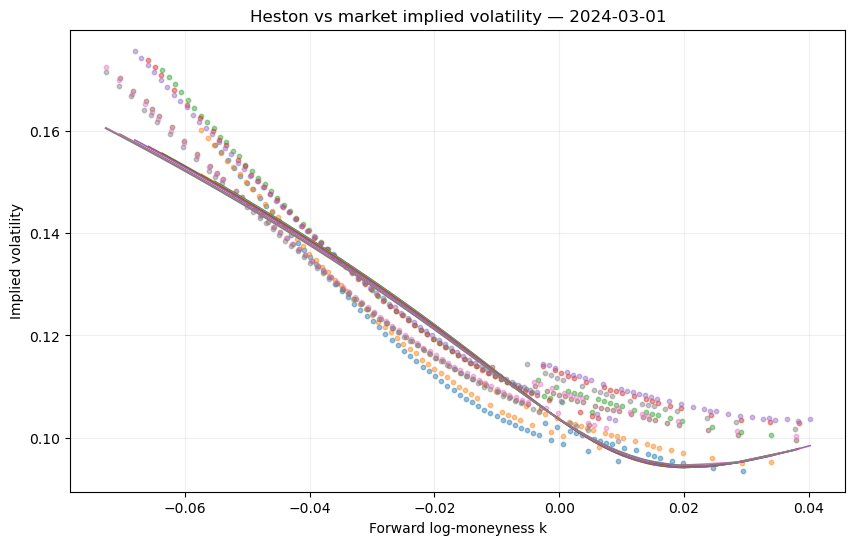

In [16]:
example_date = pd.Timestamp(EXAMPLE_DATE) if EXAMPLE_DATE is not None else pd.Timestamp(sorted(same_day_otm["date"].unique())[0])
day = same_day_otm.loc[same_day_otm["date"] == example_date]

fig, ax = plt.subplots(figsize=(10, 6))
for T, g in list(day.groupby("T"))[:8]:
    ax.scatter(g["k"], g["iv_market_otm"], s=10, alpha=0.45)
    order = np.argsort(g["k"].to_numpy())
    ax.plot(g["k"].to_numpy()[order], g["heston_iv"].to_numpy()[order], lw=1.2)
ax.set(
    title=f"Heston vs market implied volatility — {example_date.date()}",
    xlabel="Forward log-moneyness k", ylabel="Implied volatility"
)
ax.grid(alpha=0.2)
plt.show()

## 14. COS delta and finite-difference validation

The COS price contains terms of the form

$$
e^{iu\log(S/K)}.
$$

Therefore

$$
\frac{\partial}{\partial S}e^{iu\log(S/K)}
=
\frac{iu}{S}e^{iu\log(S/K)}.
$$

The spot delta is obtained from the same COS sum almost for free. The finite-difference check below validates the implementation on a small sample while holding the calibrated parameters and carry inputs fixed.

In [17]:
probe = same_day_all.loc[same_day_all["date"] == example_date].head(100).copy()
p = param_by_date[example_date]
pars = [p["v0"], p["theta"], p["kappa"], p["xi"], p["rho"]]
S0 = float(probe["S"].iloc[0]); h = 0.50

_, delta_analytic = heston_cos_price_delta(
    S0, probe["K"], probe["T"], probe["r"], probe["q"], probe["cp_flag"],
    *pars, N=COS_N_EVALUATION
)
price_up, _ = heston_cos_price_delta(
    S0+h, probe["K"], probe["T"], probe["r"], probe["q"], probe["cp_flag"],
    *pars, N=COS_N_EVALUATION
)
price_dn, _ = heston_cos_price_delta(
    S0-h, probe["K"], probe["T"], probe["r"], probe["q"], probe["cp_flag"],
    *pars, N=COS_N_EVALUATION
)
delta_fd = (price_up-price_dn)/(2*h)

print("Analytic-vs-finite-difference delta RMS:", np.sqrt(np.mean((delta_analytic-delta_fd)**2)))
print("Maximum absolute delta difference:", np.max(np.abs(delta_analytic-delta_fd)))

Analytic-vs-finite-difference delta RMS: 4.370755151474882e-07
Maximum absolute delta difference: 9.594321723760402e-07


## 15. Common daily discount and forward curves for hedge carry

Pricing each option uses its observed maturity-specific $F$ and $D$. The one-day self-financing hedge additionally needs interest and dividend carry between two trading dates.

This copies the LV notebook's PCHIP construction of daily $\log D(u)$ and $\log(F(u)/S)$, so the Heston and LV hedge accounting conventions are identical.

In [18]:
@dataclass
class DailyMarketCurve:
    date: pd.Timestamp
    am_settlement: int
    spot: float
    T_nodes: np.ndarray
    logD_nodes: np.ndarray
    logF_nodes: np.ndarray

    def __post_init__(self):
        self._logD = PchipInterpolator(self.T_nodes, self.logD_nodes, extrapolate=True)
        self._logF = PchipInterpolator(self.T_nodes, self.logF_nodes, extrapolate=True)

    def log_discount(self, t):
        return self._logD(np.maximum(np.asarray(t, float), 0.0))

    def log_forward_ratio(self, t):
        return self._logF(np.maximum(np.asarray(t, float), 0.0))

    def discount(self, t0, t1):
        return np.exp(self.log_discount(t1) - self.log_discount(t0))

    def q_integral(self, t0, t1):
        return (
            -(self.log_discount(t1)-self.log_discount(t0))
            -(self.log_forward_ratio(t1)-self.log_forward_ratio(t0))
        )

class CurveBook:
    def __init__(self, spot_raw, forwards_raw, rates_raw):
        self.spot = spot_raw.loc[spot_raw["secid"] == SECID, ["date", "close"]].copy()
        self.spot["date"] = pd.to_datetime(self.spot["date"])
        self.spot = self.spot.set_index("date")["close"].to_dict()

        self.forwards = forwards_raw.loc[forwards_raw["secid"] == SECID].copy()
        self.forwards["date"] = pd.to_datetime(self.forwards["date"])
        self.forwards["expiration"] = pd.to_datetime(self.forwards["expiration"])

        self.rates = rates_raw.copy()
        self.rates["date"] = pd.to_datetime(self.rates["date"])
        self.rates["rate_decimal"] = pd.to_numeric(self.rates["rate"], errors="coerce") / 100.0
        self._cache = {}

    def get(self, date, am_settlement):
        date, am = pd.Timestamp(date), int(am_settlement)
        key = (date, am)
        if key in self._cache:
            return self._cache[key]

        S0 = float(self.spot[date])

        rg = self.rates.loc[
            self.rates["date"] == date, ["days", "rate_decimal"]
        ].dropna().sort_values("days")
        T_r = rg["days"].to_numpy(float) / 365.0
        logD = -rg["rate_decimal"].to_numpy(float) * T_r

        fg = self.forwards.loc[
            (self.forwards["date"] == date) & (self.forwards["AMSettlement"] == am),
            ["expiration", "ForwardPrice"]
        ].copy()
        if len(fg) < 2:
            fg = self.forwards.loc[
                self.forwards["date"] == date, ["expiration", "ForwardPrice"]
            ].copy()

        fg["T"] = (fg["expiration"] - date).dt.days / 365.0
        fg = (
            fg.loc[(fg["T"] >= 0) & (fg["ForwardPrice"] > 0)]
            .groupby("T", as_index=False)["ForwardPrice"].mean().sort_values("T")
        )
        T_f = fg["T"].to_numpy(float)
        logF = np.log(fg["ForwardPrice"].to_numpy(float) / S0)

        positive_f = T_f > 0
        T_f, logF = T_f[positive_f], logF[positive_f]

        T_all = np.unique(np.concatenate([[0.0], T_r, T_f]))
        logD_all = np.interp(T_all, np.r_[0.0, T_r], np.r_[0.0, logD])
        logF_all = np.interp(T_all, np.r_[0.0, T_f], np.r_[0.0, logF])

        curve = DailyMarketCurve(date, am, S0, T_all, logD_all, logF_all)
        self._cache[key] = curve
        return curve

curve_book = CurveBook(spot_raw, forwards_raw, rates_raw)

## 16. Identical-contract next-day pairs

In [19]:
def build_evaluation_pairs(quotes):
    trading_dates = sorted(quotes["date"].unique())
    next_date = {
        trading_dates[i]: trading_dates[i+1]
        for i in range(len(trading_dates)-1)
    }

    left = quotes.copy()
    left["next_date"] = left["date"].map(next_date)

    cols = [
        "date", "optionid", "cp_flag", "K", "exdate", "am_settlement",
        "mid", "bid", "ask", "S", "F", "D", "r", "q", "carry", "T", "k"
    ]
    right = quotes[cols].rename(columns={
        "date": "next_date", "mid": "mid_next", "bid": "bid_next", "ask": "ask_next",
        "S": "S_next", "F": "F_next", "D": "D_next", "r": "r_next",
        "q": "q_next", "carry": "carry_next", "T": "T_next", "k": "k_next"
    })

    return left.merge(
        right,
        on=["next_date", "optionid", "cp_flag", "K", "exdate", "am_settlement"],
        how="inner", validate="many_to_one"
    )

evaluation_pairs = build_evaluation_pairs(quotes_all)
print("Identical-contract one-day pairs:", len(evaluation_pairs))

Identical-contract one-day pairs: 173833


## 17. Rolling frozen-Heston pricing and one-day delta hedge

For a transition $t\to t+1$:

1. calibrate $(v_0,\theta,\kappa,\xi,\rho)$ using day $t$ options;
2. compute day-$t$ Heston price and $\Delta_t=\partial_S V_t$;
3. **freeze all five Heston quantities**;
4. reprice the identical contract with day-$t+1$ spot, forward, discount factor and remaining maturity.

The headline experiment deliberately freezes $v_0$ as well. Propagating its conditional mean gave only a small improvement and is better treated as a later robustness check.

The hedge uses the same theoretical spot-index accounting as the LV notebook:

$$
\varepsilon_{t,t+1}
=
V^{mkt}_{t+1}-V^{mkt}_{t}
-\Delta_t(S_{t+1}-S_t)
-\Delta_t S_t\int_t^{t+1}q(u)\,du
-B_t\left(D(t,t+1)^{-1}-1\right),
$$

where $B_t=V_t^{mkt}-\Delta_tS_t$.

In [20]:
def rolling_heston_backtest(max_transitions=None):
    dates = sorted(pd.to_datetime(heston_params["date"].unique()))
    transitions = list(zip(dates[:-1], dates[1:]))
    if max_transitions is not None:
        transitions = transitions[:max_transitions]

    outputs = []

    for d0, d1 in tqdm(transitions, desc="Rolling Heston", unit="transition"):
        g = evaluation_pairs.loc[
            (evaluation_pairs["date"] == d0)
            & (evaluation_pairs["next_date"] == d1)
        ].copy()

        if g.empty:
            continue

        p = param_by_date[d0]
        pars = [p["v0"], p["theta"], p["kappa"], p["xi"], p["rho"]]

        price0, delta0 = heston_cos_price_delta(
            float(g["S"].iloc[0]), g["K"], g["T"], g["r"], g["q"], g["cp_flag"],
            *pars, N=COS_N_EVALUATION, L=COS_L
        )
        price1, _ = heston_cos_price_delta(
            float(g["S_next"].iloc[0]), g["K"], g["T_next"], g["r_next"], g["q_next"], g["cp_flag"],
            *pars, N=COS_N_EVALUATION, L=COS_L
        )

        dt = (d1-d0).days / 365.0
        q_integral = np.empty(len(g))
        cash_interest = np.empty(len(g))

        for am, idx in g.groupby("am_settlement").groups.items():
            curve0 = curve_book.get(d0, am)
            ii = g.index.get_indexer(idx)
            q_integral[ii] = float(curve0.q_integral(0.0, dt))

            cash0 = (
                g.loc[idx, "mid"].to_numpy(float)
                - delta0[ii] * g.loc[idx, "S"].to_numpy(float)
            )
            cash_interest[ii] = cash0 * (
                1.0/float(curve0.discount(0.0, dt)) - 1.0
            )

        dividend_income = delta0 * g["S"].to_numpy(float) * q_integral

        hedge_error = (
            g["mid_next"].to_numpy(float) - g["mid"].to_numpy(float)
            - delta0 * (g["S_next"].to_numpy(float) - g["S"].to_numpy(float))
            - dividend_income - cash_interest
        )

        out = g[[
            "date", "next_date", "optionid", "cp_flag", "K", "exdate",
            "am_settlement", "T", "k", "mid", "mid_next", "bid_next", "ask_next"
        ]].copy()

        out["model_price_t"] = price0
        out["model_price_next"] = price1
        out["delta_t"] = delta0
        out["next_day_pricing_error"] = out["model_price_next"] - out["mid_next"]
        out["next_day_inside_bid_ask"] = out["model_price_next"].between(
            out["bid_next"], out["ask_next"]
        )
        out["hedging_error"] = hedge_error
        out["unhedged_change"] = out["mid_next"] - out["mid"]
        outputs.append(out)

    return pd.concat(outputs, ignore_index=True) if outputs else pd.DataFrame()

if ROLLING_CACHE.exists() and not FORCE_REBUILD_ROLLING:
    rolling_results = pd.read_pickle(ROLLING_CACHE)
    print("Loaded rolling cache.")
elif RUN_ROLLING_BACKTEST:
    rolling_results = rolling_heston_backtest(MAX_ROLLING_TRANSITIONS)
    atomic_pickle(rolling_results, ROLLING_CACHE)
else:
    rolling_results = pd.DataFrame()
    print("Rolling backtest disabled.")

Rolling Heston:   0%|          | 0/19 [00:00<?, ?transition/s]

## 18. Summary metrics and regional diagnostics

In [21]:
def metric_summary(df):
    if df.empty:
        return pd.Series(dtype=float)

    hedge_mae = df["hedging_error"].abs().mean()
    unhedged_mae = df["unhedged_change"].abs().mean()

    return pd.Series({
        "n": len(df),
        "next_day_RMSE": np.sqrt(np.mean(df["next_day_pricing_error"]**2)),
        "next_day_MAE": df["next_day_pricing_error"].abs().mean(),
        "next_day_inside_bid_ask": df["next_day_inside_bid_ask"].mean(),
        "hedging_RMSE": np.sqrt(np.mean(df["hedging_error"]**2)),
        "hedging_MAE": hedge_mae,
        "hedging_bias": df["hedging_error"].mean(),
        "unhedged_MAE": unhedged_mae,
        "hedging_improvement": 1.0 - hedge_mae/unhedged_mae,
    })

if not rolling_results.empty:
    display(metric_summary(rolling_results).to_frame("rolling_Heston"))

    rolling_results["dte_bucket"] = pd.cut(
        rolling_results["T"]*365, [0, 30, 60, 90, 180, 365, np.inf]
    )
    rolling_results["abs_k_bucket"] = pd.cut(
        rolling_results["k"].abs(), [0, 0.025, 0.05, 0.10, 0.20, 0.30, np.inf]
    )

    display(rolling_results.groupby("dte_bucket", observed=True).apply(metric_summary))
    display(rolling_results.groupby("abs_k_bucket", observed=True).apply(metric_summary))

,rolling_Heston
n,173833.000000
next_day_RMSE,6.797141
next_day_MAE,5.242571
next_day_inside_bid_ask,0.122134
hedging_RMSE,2.776875
hedging_MAE,2.108897
hedging_bias,-0.327601
unhedged_MAE,13.904121
hedging_improvement,0.848326


,n,next_day_RMSE,next_day_MAE,next_day_inside_bid_ask,hedging_RMSE,hedging_MAE,hedging_bias,unhedged_MAE,hedging_improvement
dte_bucket,,,,,,,,,
"(0.0, 30.0]",32641.0,3.714827,2.960328,0.186820,2.730532,2.103867,-0.487592,13.643288,0.845795
"(30.0, 60.0]",37624.0,5.050431,4.023958,0.159978,2.758757,2.094363,-0.430060,14.298318,0.853524
"(60.0, 90.0]",19062.0,6.139756,4.919853,0.119610,2.641367,2.004583,-0.153572,14.548938,0.862218
"(90.0, 180.0]",60671.0,7.628671,6.217366,0.090109,2.849813,2.155951,-0.306020,13.914528,0.845058
"(180.0, 365.0]",23835.0,9.975316,8.068399,0.057353,2.785928,2.102377,-0.140879,13.096893,0.839475


,n,next_day_RMSE,next_day_MAE,next_day_inside_bid_ask,hedging_RMSE,hedging_MAE,hedging_bias,unhedged_MAE,hedging_improvement
abs_k_bucket,,,,,,,,,
"(0.0, 0.025]",51178.0,5.523761,4.402577,0.114913,3.135514,2.432834,-0.626434,13.612608,0.821281
"(0.025, 0.05]",38914.0,5.004740,3.955652,0.203320,2.641466,2.028254,-0.345114,13.314454,0.847665
"(0.05, 0.1]",41390.0,6.189011,4.813367,0.129621,2.558912,1.931399,-0.209031,13.566876,0.857639
"(0.1, 0.2]",32978.0,8.667274,6.982762,0.059039,2.574858,1.918175,-0.110945,14.679486,0.869330
"(0.2, 0.3]",9373.0,12.361631,10.944589,0.013443,2.849364,2.129800,0.090910,16.705142,0.872506


## 19. Why this is the reference Heston baseline

The March 2024 pilot deliberately tested whether extra machinery earned its place.

**Retained**

- five-parameter risk-neutral Heston;
- actual OptionMetrics forwards and discount factors;
- vectorised COS pricing;
- vega-normalised least squares;
- up to 25 evenly spread calibration quotes per maturity;
- first-day multistart plus daily warm starts;
- transformed parameters with broad numerical bounds;
- no Feller constraint;
- analytic COS spot delta;
- identical-contract next-day pricing and the same hedge accounting as LV.

**Not adopted in the headline model**

- raw-dollar price least squares: slightly improved same-day fit but worsened next-day pricing;
- bid--ask weighting: did not materially solve the structural Heston fit limitation;
- every quote in the optimiser: much slower for little gain;
- global optimisation every day: unnecessary once warm starts were validated;
- minimum-variance $V_S+\rho\xi V_v/S$ hedge: unstable across dates;
- conditional-mean propagation of $v_0$: small improvement, retained only as a possible robustness test.

This makes Heston the first baseline in the project with a genuine non-traded stochastic volatility state, while remaining far more parsimonious than the neural SDE.

### References

- Heston (1993), *A Closed-Form Solution for Options with Stochastic Volatility with Applications to Bond and Currency Options*.
- Gatheral (2006), *The Volatility Surface*, Chapter 2.
- Fang and Oosterlee (2008), *A Novel Pricing Method for European Options Based on Fourier-Cosine Series Expansions*.
- Albrecher et al. (2007), *The Little Heston Trap*.
- Cui, del Baño Rollin and Germano (2017), *Full and fast calibration of the Heston stochastic volatility model*.
- `ted-love/Heston_Calibration`, used as an implementation reference for vectorised COS calibration.